<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Data Visualization: Bar Charts and Comparative Analysis**
**IBM Skills Network guided lab | Portfolio edition**

### Project Overview
This notebook explores developer survey responses through ten visualizations. Although the lab focuses on bar charts, it also uses a histogram, box plot, scatter plot, and bubble plot to examine compensation, age, professional background, technology interests, and survey participation.

**Guiding question:** What do the survey results reveal about developer compensation, technology use, and respondent demographics, and how should those patterns be interpreted?

**Approach:** Load and prepare the survey data, create visual summaries, compare relevant groups, and interpret each chart based on its saved output.

**Tools and methods:** Python, Pandas, Matplotlib, frequency counts, median comparisons, IQR filtering, and categorical analysis.

*This portfolio edition retains the original IBM Skills Network learning workflow and adds evidence-based interpretations in clear, professional language.*

Estimated time needed: **30** minutes


### Objectives


In this lab you will perform the following:
-   Visualize the distribution of data
-   Visualize the relationship between two features
-   Visualize the composition of data
-   Visualize comparison of data

### Setup: Working with the Database
**Install the needed libraries**


In [1]:
!pip install pandas
!pip install seaborn 

In [2]:
!pip install matplotlib

**Download and connect to the database file containing survey data.**


To start, download and load the dataset into a `pandas` DataFrame.



In [3]:
# Step 1: Download the dataset
!wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

# Step 2: Import necessary libraries and load the dataset
import pandas as pd
import matplotlib.pyplot as plt

# Load the data
df = pd.read_csv("survey-data.csv")

# Display the first few rows to understand the structure of the data
df.head()

--2026-10-15 12:13:06--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 
200 OK
Length: 159525875 (152M) [text/csv]
Saving to: ‘survey-data.csv’

survey-data.csv       0%[                    ]       0  --.-KB/s               
survey-data.csv       0%[                    ]   1.43M  6.79MB/s               
survey-data.csv       0%[                    ]   1.45M  1.37MB/s               
survey-data.csv       2%[                    ]   3.45M  1.99MB/s               
survey-data.csv       4%[                    ]   6.22M  2.83MB/s               
survey-data.csv       5%[>             

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Visualizing Data Distributions


##### 1. Histogram of `ConvertedCompYearly`


Visualize the distribution of yearly compensation (`ConvertedCompYearly`) using a histogram.



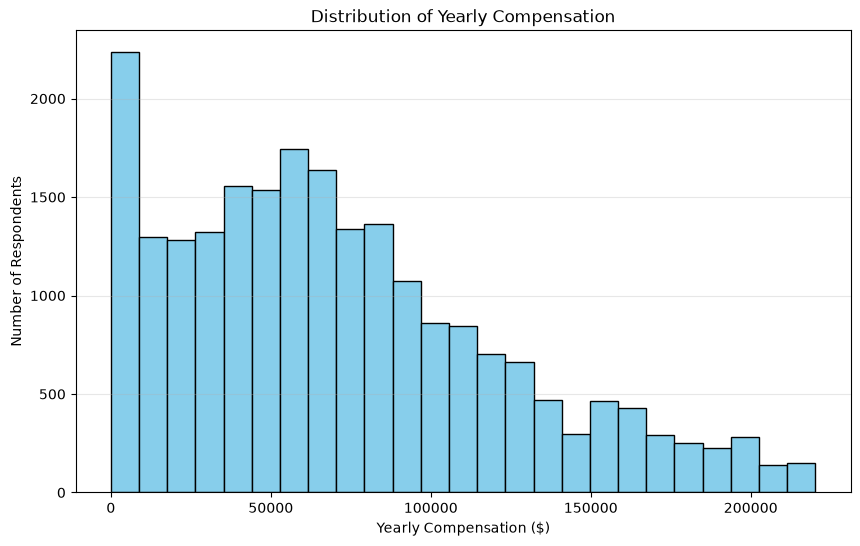

In [6]:
## Write your code here
df_t1 = df.dropna(subset=['ConvertedCompYearly']).copy()

Q1 = df_t1['ConvertedCompYearly'].quantile(0.25)
Q3 = df_t1['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1
df_t1_clean = df_t1[df_t1['ConvertedCompYearly'] <= (Q3 + 1.5 * IQR)]

plt.figure(figsize=(10, 6))
plt.hist(df_t1_clean['ConvertedCompYearly'], bins=25, color='skyblue', edgecolor='black')
plt.title('Distribution of Yearly Compensation')
plt.xlabel('Yearly Compensation ($)')
plt.ylabel('Number of Respondents')
plt.grid(axis='y', alpha=0.3)
plt.show()

The distribution is right-skewed. Most reported annual compensation values are concentrated toward the lower and middle parts of the displayed range, while the number of respondents generally declines at higher compensation levels. The tallest bar is in the lowest compensation interval, and another noticeable concentration appears around $40,000-$80,000.

**What this suggests:** Compensation varies substantially across the surveyed developers, and a relatively small share of the displayed records falls in the highest salary intervals. A single average would not describe this distribution as clearly as a median alongside the spread.

##### 2. Box Plot of `Age`


Since `Age` is categorical in the dataset, convert it to numerical values for a box plot.



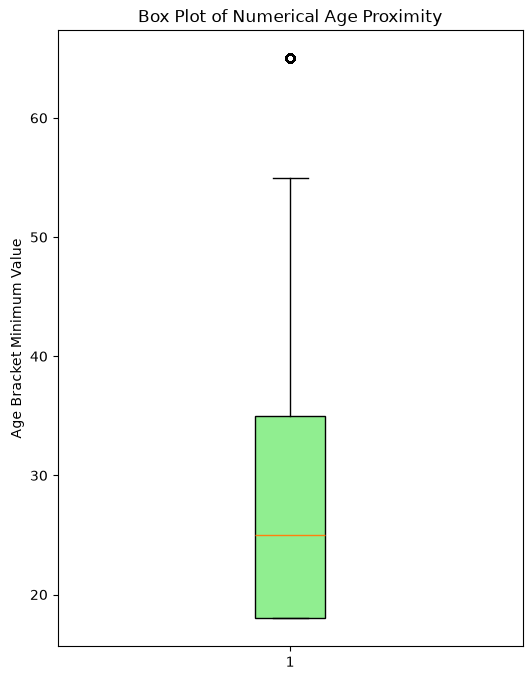

In [7]:
## Write your code here
df_t2= df[['Age']].dropna().copy()
df_t2['Age_numeric'] = pd.to_numeric(df_t2['Age'].astype(str).str.extract(r'(\d+)').iloc[:, 0], errors='coerce')
df_t2 = df_t2.dropna(subset=['Age_numeric'])

plt.figure(figsize=(6, 8))
plt.boxplot(df_t2['Age_numeric'], patch_artist=True, boxprops=dict(facecolor='lightgreen'))
plt.title('Box Plot of Numerical Age Proximity')
plt.ylabel('Age Bracket Minimum Value')
plt.show()

The median of the numeric age-bracket values is approximately 25, and the middle half of the plotted values extends from roughly 18 to 35. The upper whisker reaches about 55, while a value near 65 appears as an outlier.

**What this suggests:** The survey responses are concentrated in younger adult age categories, with fewer observations in older brackets. The chart is useful for seeing how the coded age categories are distributed.

### Task 2: Visualizing Relationships in Data


##### 1. Scatter Plot of `Age_numeric` and `ConvertedCompYearly`


Explore the relationship between age and compensation.



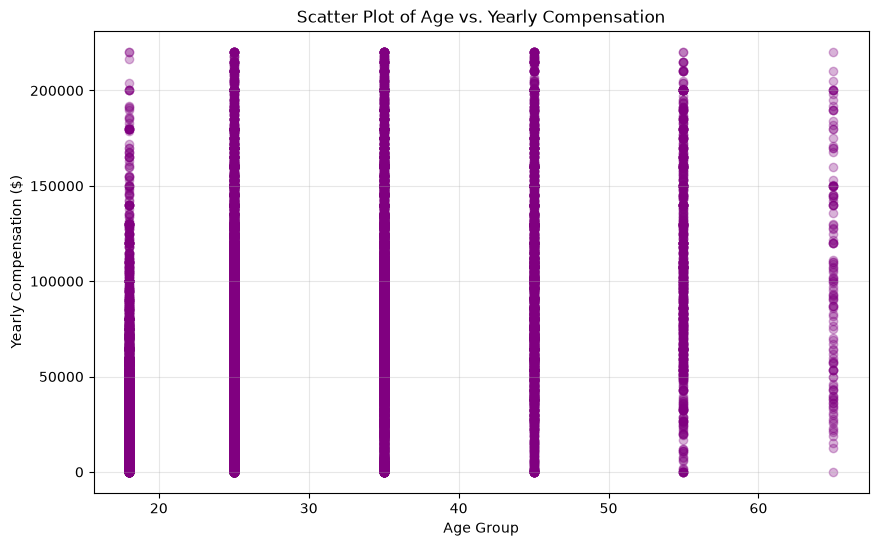

In [9]:
## Write your code here
df_t3 = df.dropna(subset=['Age', 'ConvertedCompYearly']).copy()
df_t3['Age_numeric'] = pd.to_numeric(df_t3['Age'].astype(str).str.extract(r'(\d+)').iloc[:, 0], errors='coerce')
df_t3 = df_t3.dropna(subset=['Age_numeric'])

Q1 = df_t3['ConvertedCompYearly'].quantile(0.25)
Q3 = df_t3['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1
df_t3_clean = df_t3[df_t3['ConvertedCompYearly'] <= (Q3 + 1.5 * IQR)]

plt.figure(figsize=(10, 6))
plt.scatter(df_t3_clean['Age_numeric'], df_t3_clean['ConvertedCompYearly'], alpha=0.3, color='purple')
plt.title('Scatter Plot of Age vs. Yearly Compensation')
plt.xlabel('Age Group')
plt.ylabel('Yearly Compensation ($)')
plt.grid(True, alpha=0.3)
plt.show()

The points form distinct vertical bands because each age category was converted to a single numeric value. Compensation varies widely within nearly every age group, with reported values spanning much of the displayed range.

**What this suggests:** Age category alone does not explain compensation. Respondents in the same age group can report very different salaries, and the chart does not show a simple, consistent increase across the individual records.

##### 2. Bubble Plot of `ConvertedCompYearly` and `JobSatPoints_6` with `Age_numeric` as Bubble Size


Explore how compensation and job satisfaction are related, with age as the bubble size.


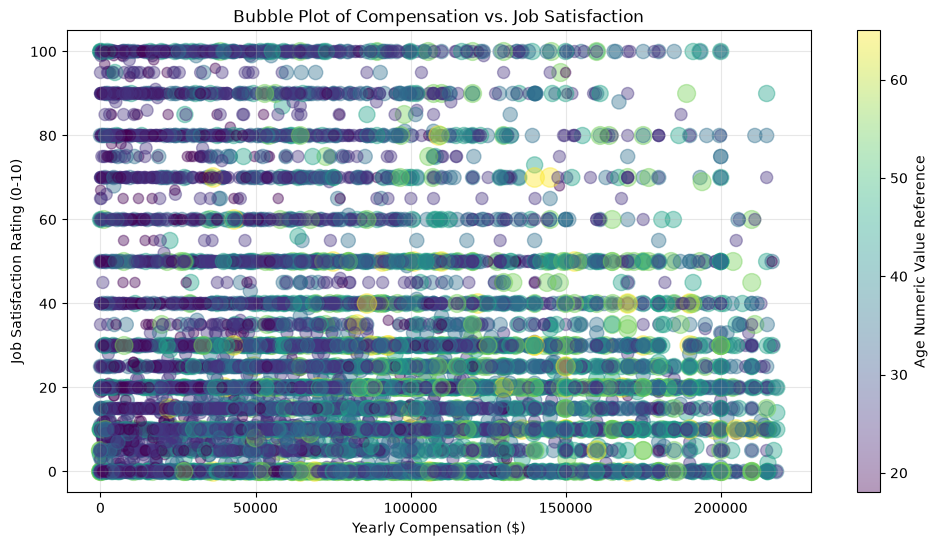

In [10]:
## Write your code here
df_t4 = df.dropna(subset=['ConvertedCompYearly', 'JobSatPoints_6', 'Age']).copy()
df_t4['Age_numeric'] = pd.to_numeric(df_t4['Age'].astype(str).str.extract(r'(\d+)').iloc[:, 0], errors='coerce')
df_t4['JobSatPoints_6'] = df_t4['JobSatPoints_6'].astype(int)
df_t4 = df_t4.dropna(subset=['Age_numeric'])

Q1 = df_t4['ConvertedCompYearly'].quantile(0.25)
Q3 = df_t4['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1
df_t4_clean = df_t4[df_t4['ConvertedCompYearly'] <= (Q3 + 1.5 * IQR)]

plt.figure(figsize=(12, 6))
plt.scatter(
    df_t4_clean['ConvertedCompYearly'], 
    df_t4_clean['JobSatPoints_6'], 
    s=df_t4_clean['Age_numeric'] * 3, 
    c=df_t4_clean['Age_numeric'],    
    alpha=0.4, 
    cmap='viridis'
)
plt.title('Bubble Plot of Compensation vs. Job Satisfaction')
plt.xlabel('Yearly Compensation ($)')
plt.ylabel('Job Satisfaction Rating (0-10)')
plt.colorbar(label='Age Numeric Value Reference')
plt.grid(True, alpha=0.3)
plt.show()

The saved bubble plot shows a broad spread of the JobSatPoints_6 measure at both lower and higher compensation levels. Many points appear at lower measure values, while some extend toward 100. Bubble colors and sizes vary by age category, but the overlapping markers make age-based patterns difficult to isolate.

**What this suggests:** There is no obvious one-to-one relationship between compensation and the plotted survey measure. People with similar reported compensation can have substantially different values on that measure.

### Task 3: Visualizing Composition of Data with Bar Charts


##### 1. Horizontal Bar Chart of `MainBranch` Distribution


Visualize the distribution of respondents’ primary roles to understand their professional focus.



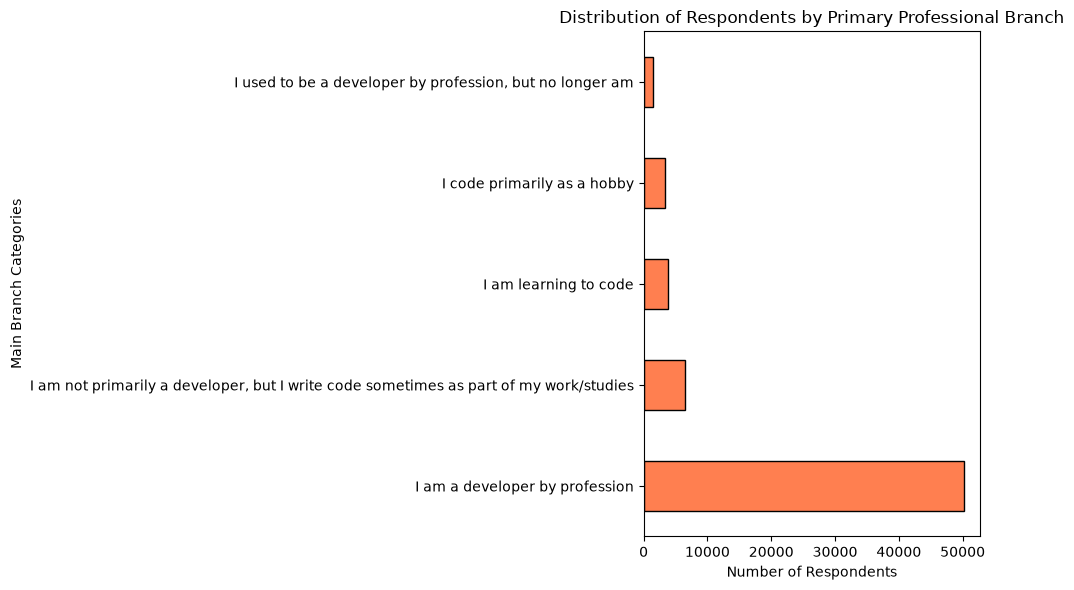

In [11]:
## Write your code here
main_branch_count = df['MainBranch'].value_counts()

plt.figure(figsize=(10, 6))
main_branch_count.plot(kind='barh', color='coral', edgecolor='black')
plt.title('Distribution of Respondents by Primary Professional Branch')
plt.xlabel('Number of Respondents')
plt.ylabel('Main Branch Categories')
plt.tight_layout()
plt.show()

The category "I am a developer by profession" dominates the chart, with approximately 50,000 responses. The next largest category-people who are not primarily developers but write code as part of work or study-is far smaller. Learning to code, coding as a hobby, and previously working as a developer account for smaller groups.

**What this suggests:** The dataset largely reflects the experiences of professional developers. That context matters when interpreting later charts about compensation, tools, and working conditions.

##### 2. Vertical Bar Chart of Top 5 Programming Languages Respondents Want to Work With


Identify the most desired programming languages based on `LanguageWantToWorkWith`.



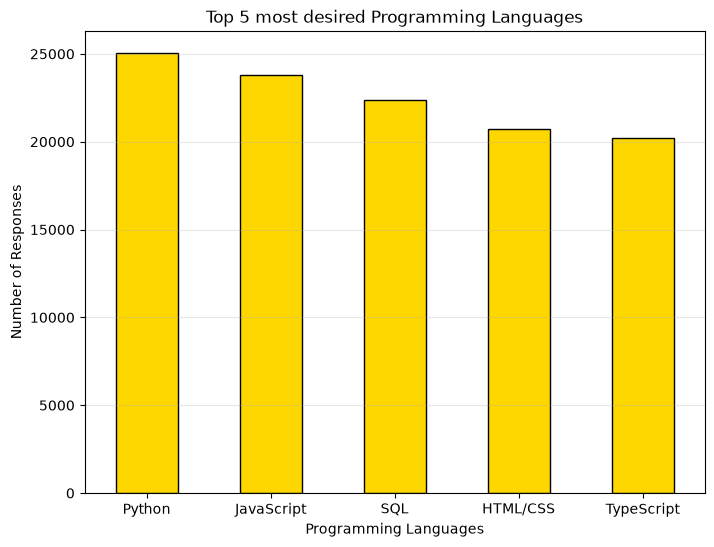

In [12]:
## Write your code here
languages_exploded = df['LanguageWantToWorkWith'].dropna().str.split(';').explode()
top_5_lang = languages_exploded.value_counts().head(5)

plt.figure(figsize=(8, 6))
top_5_lang.plot(kind='bar', color='gold', edgecolor='black')
plt.title('Top 5 most desired Programming Languages')
plt.xlabel('Programming Languages')
plt.ylabel('Number of Responses')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()

Python has the highest number of mentions, at approximately 25,000, followed by JavaScript at about 24,000. SQL, HTML/CSS, and TypeScript follow, each with more than 20,000 mentions in the saved chart.

**What this suggests:** These five languages and technologies attract substantial interest among respondents who answered the future-use question. Python and JavaScript lead the selected group, but the differences between the five are not especially large.

##### 3. Stacked Bar Chart of Median `JobSatPoints_6` and `JobSatPoints_7` by Age Group


Compare job satisfaction metrics across different age groups with a stacked bar chart.


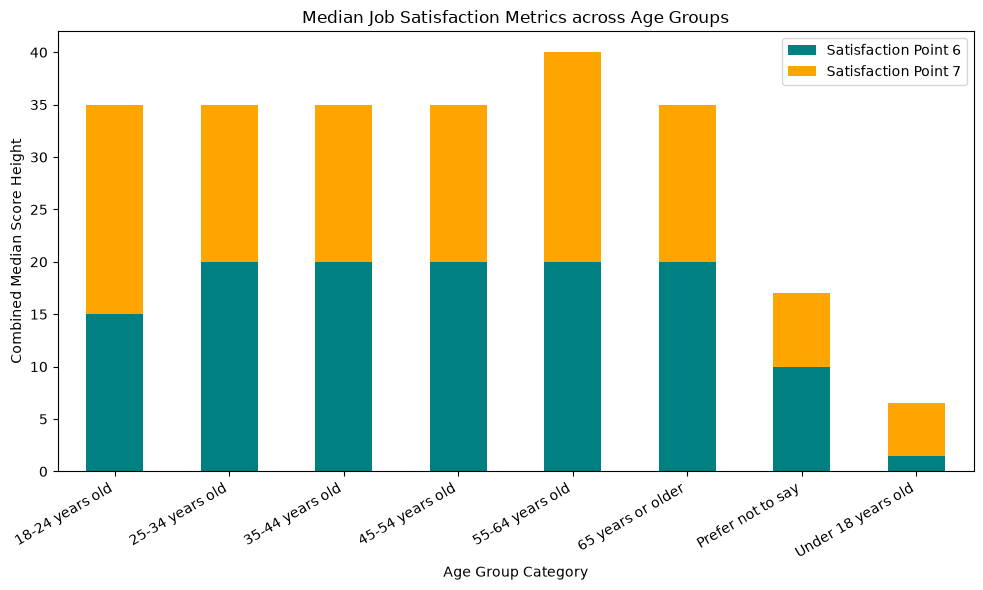

In [13]:
## Write your code here
df_sat_grp = df.groupby('Age')[['JobSatPoints_6', 'JobSatPoints_7']].median()

df_sat_grp.plot(kind='bar', stacked=True, figsize=(10, 6), color=['teal', 'orange'])
plt.title('Median Job Satisfaction Metrics across Age Groups')
plt.xlabel('Age Group Category')
plt.ylabel('Combined Median Score Height')
plt.xticks(rotation=30, ha='right')
plt.legend(['Satisfaction Point 6', 'Satisfaction Point 7'])
plt.tight_layout()
plt.show()

The combined stacked bars are approximately 35 for most adult age categories, with the 55-64 category reaching around 40. The "prefer not to say" and under-18 categories are substantially lower. The teal and orange segments contribute different amounts across age groups.

**What this suggests:** The two recorded satisfaction-point fields vary across age categories, but the total height should not be treated as a single measure of job satisfaction.

##### 4. Bar Chart of Database Popularity (`DatabaseHaveWorkedWith`)


Identify the most commonly used databases among respondents by visualizing `DatabaseHaveWorkedWith`.



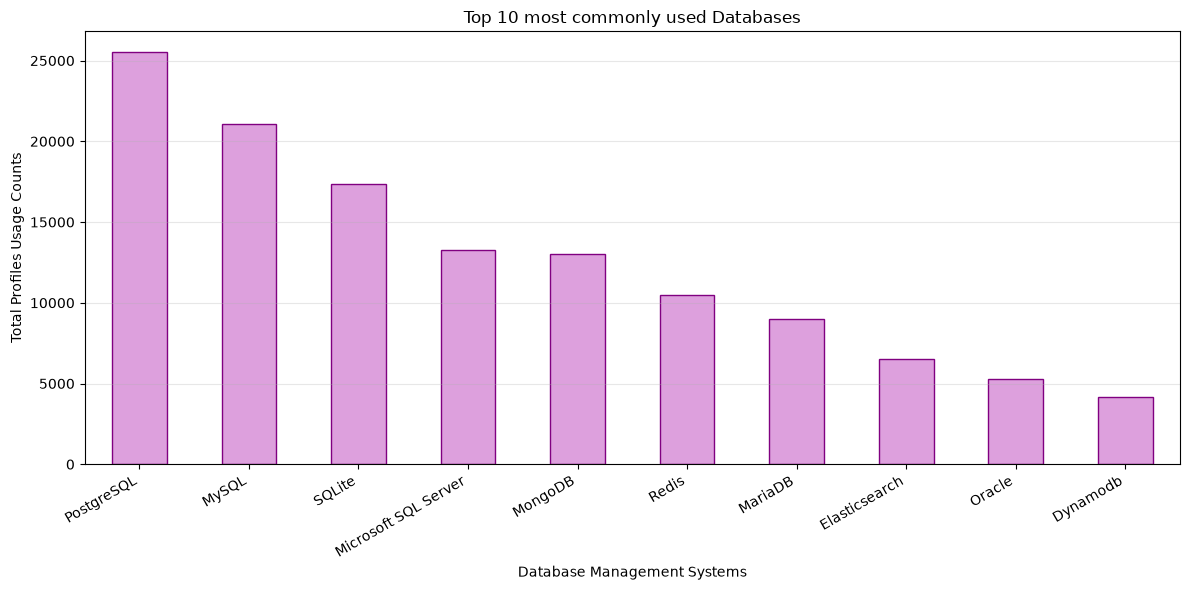

In [14]:
## Write your code here
databases_exploded = df['DatabaseHaveWorkedWith'].dropna().str.split(';').explode()
top_10_db = databases_exploded.value_counts().head(10)

plt.figure(figsize=(12, 6))
top_10_db.plot(kind='bar', color='plum', edgecolor='purple')
plt.title('Top 10 most commonly used Databases')
plt.xlabel('Database Management Systems')
plt.ylabel('Total Profiles Usage Counts')
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

PostgreSQL is the most frequently mentioned database, at roughly 25,000 selections, followed by MySQL at approximately 21,000 and SQLite at about 17,000. Microsoft SQL Server and MongoDB are also prominent. The remaining databases have smaller but still substantial mention counts.

**What this suggests:** Relational database technologies account for several of the highest-frequency responses, while non-relational technologies such as MongoDB and Redis also appear among the top ten.

### Task 4: Visualizing Comparison of Data with Bar Charts


##### 1. Grouped Bar Chart of Median `ConvertedCompYearly` for Different Age Groups


Compare median compensation across multiple age groups with a grouped bar chart.



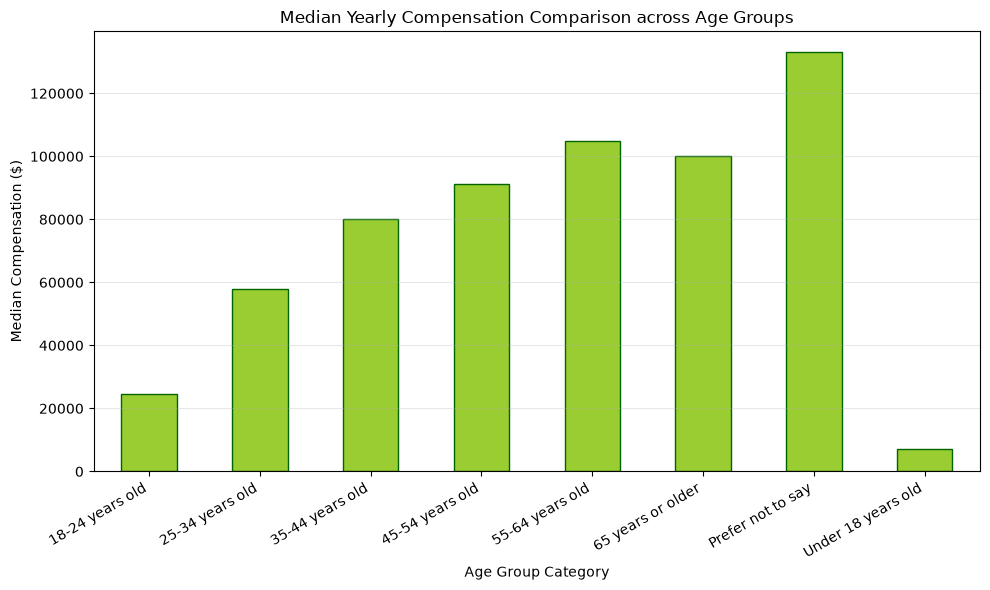

In [15]:
## Write your code here
df_t5 = df.dropna(subset=['ConvertedCompYearly', 'Age']).copy()

Q1 = df_t5['ConvertedCompYearly'].quantile(0.25)
Q3 = df_t5['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1
df_t5_clean = df_t5[df_t5['ConvertedCompYearly'] <= (Q3 + 1.5 * IQR)]

age_comp_median = df_t5_clean.groupby('Age')['ConvertedCompYearly'].median()

plt.figure(figsize=(10, 6))
age_comp_median.plot(kind='bar', color='yellowgreen', edgecolor='darkgreen')
plt.title('Median Yearly Compensation Comparison across Age Groups')
plt.xlabel('Age Group Category')
plt.ylabel('Median Compensation ($)')
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Median reported annual compensation increases from roughly $25,000 in the 18-24 group to about $58,000 for ages 25-34, $80,000 for 35-44, and $91,000 for 45-54. The 55-64 group is around $105,000, followed by approximately $100,000 for respondents aged 65 or older.

The "prefer not to say" group appears highest, at approximately $133,000, but that category does not represent a meaningful age range. The under-18 category is much lower.

**What this suggests:** Median compensation is generally higher in older adult groups within the filtered survey sample. This could reflect differences in seniority, roles, or geographic composition, not age alone.

##### 2. Bar Chart of Respondent Count by Country


Show the distribution of respondents by country to see which regions are most represented.



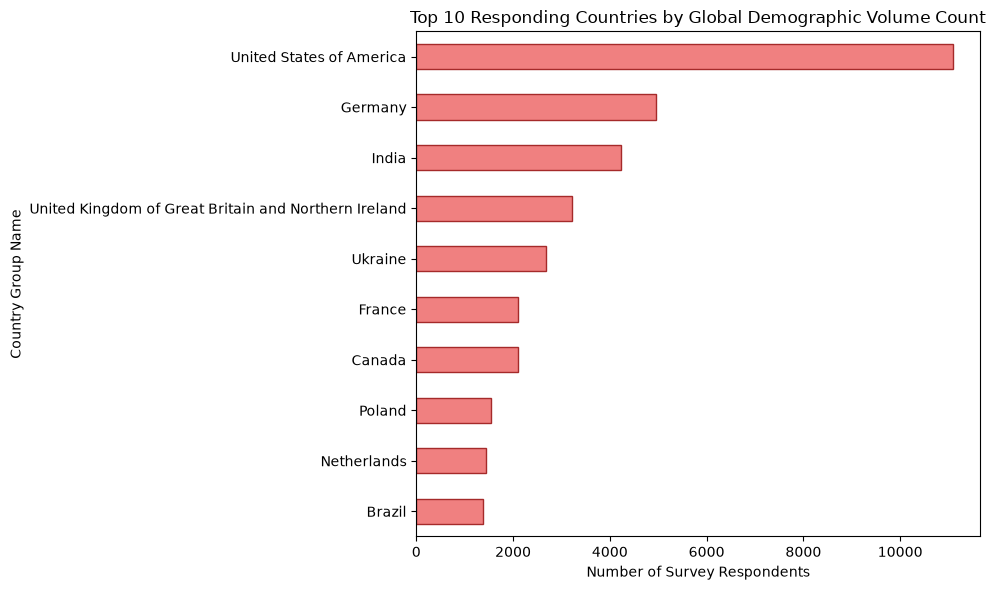

In [16]:
## Write your code here
top_10_cntry = df['Country'].dropna().value_counts().head(10)

plt.figure(figsize=(10, 6))
top_10_cntry.plot(kind='barh', color='lightcoral', edgecolor='brown')
plt.title('Top 10 Responding Countries by Global Demographic Volume Count')
plt.xlabel('Number of Survey Respondents')
plt.ylabel('Country Group Name')
plt.gca().invert_yaxis() 
plt.tight_layout()
plt.show()

The United States has the largest number of respondents, at roughly 11,000, followed by Germany (around 5,000) and India (around 4,000). The United Kingdom and Ukraine are also prominent, followed by France, Canada, Poland, the Netherlands, and Brazil.

**What this suggests:** The survey includes participants from several countries, but representation is uneven. The United States contributes substantially more responses than any other country shown.

### Key Findings
- Compensation varies widely, with a right-skewed distribution after upper-outlier filtering.
- Median compensation generally increases across adult age categories in the saved results, but this is not evidence of individual salary growth.
- Professional developers account for most survey responses, which shapes the interpretation of technology and career-related findings.
- Python, JavaScript, SQL, HTML/CSS, and TypeScript lead the displayed desired-language mentions.
- PostgreSQL, MySQL, and SQLite lead the database-use mentions in the saved charts.
- Survey participation is geographically uneven, with the United States contributing the most responses among the countries shown.
- Satisfaction-point comparisons require additional validation, because one chart uses a 0-10 axis label for values that reach 100 and another stacks separate median measures.

### Limitations and Next Steps
This analysis describes survey respondents rather than the entire developer population. Several technology questions permit multiple selections, so counts overlap. Age brackets are categorical even when the code extracts numeric values. Compensation comparisons use filtered records and require careful treatment of geographic and currency differences. Satisfaction-field definitions and chart labels should be verified before drawing substantive conclusions.

To extend this work, I would compare percentages instead of raw counts where appropriate, include sample sizes, validate the survey measurement scales, and segment compensation by country, role, and experience.

### Skills Demonstrated
- Data preparation: Filtering missing values, separating multi-select responses, and identifying upper compensation outliers.
- Exploratory analysis: Examining distributions, frequencies, and grouped medians.
- Visualization: Creating and interpreting histograms, box plots, scatter plots, bubble plots, and bar charts.
- Analytical communication: Explaining observed patterns, measurement limitations, and useful follow-up analyses.

### Summary


After completing this lab, you will be able to:
- Create a horizontal bar chart to visualize the distribution of respondents' primary roles, helping to understand their professional focus.
- Develop a vertical bar chart to identify the most desired programming languages based on the LanguageWantToWorkWith variable.
- Use a stacked bar chart to compare job satisfaction metrics across different age groups.
- Create a bar chart to visualize the most commonly used databases among respondents using the DatabaseHaveWorkedWith variable.

Attribution: Original lab content, code, saved charts, branding, and copyright belong to IBM Skills Network. Portfolio explanations and chart interpretations were added.

### Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
